# Proyecto de Aprendizaje de Máquina 2026-20 - Parte 2
## Clasificación de sentimiento en reseñas multilingües

**Grupo 20.** Queremos predecir `negativo`, `neutral` o `positivo` a partir de una reseña.
Ahora hay textos en español, inglés, portugués, francés y mezclas de español e inglés.

Usamos mBERT para obtener embeddings y entrenamos un perceptrón multicapa (MLP).
La implementación retoma los embeddings `[CLS]` y promedio de `202610/Prácticas/Embeddings/Practica15.ipynb`
y las capas, ReLU, Dropout y parada temprana de `202620/Prácticas/P14_Redes neuronales/Perceptrón_Multicapa.ipynb`.
La práctica de MLP usa Keras; aquí escribimos esas mismas operaciones con PyTorch para
trabajar con la librería usada en la práctica de BERT.

**Aclaración del profesor:** el único Transformer de esta solución es un encoder BERT.
Se usa `AutoModel` para extraer representaciones; no se usan decoders, modelos generativos,
traducción generativa ni APIs para asignar sentimientos.

Las cifras y conclusiones se calculan al ejecutar. Generar cinco CSV no equivale a realizar
cinco envíos: los scores públicos se registran después de subir cada archivo a Kaggle.

## 1. Preparación en Kaggle

1. Importar este notebook y agregar los datos de **Parte 2 - Competencia Aprendizaje de Máquina 2026-20**.
2. En las opciones del notebook, seleccionar una GPU y activar Internet para descargar mBERT.
3. Ejecutar las celdas en orden. Si falta `langid`, ejecutar la siguiente celda de instalación.
4. Guardar una versión ejecutada con sus outputs. Los resultados quedan en `/kaggle/working/output/parte2`.

La primera descarga del encoder necesita Internet. Si se agregó una copia de mBERT como
input de Kaggle, se puede indicar su carpeta en `RUTA_ENCODER_LOCAL` y trabajar sin Internet.



**Actualización posterior informada por el grupo:** el candidato `p2_exp05_lr_aumento` obtuvo **0,70383 en Kaggle**. Ese resultado está registrado en `output/parte2/registro_kaggle.csv`. La mejora con ajuste del encoder se documenta aparte en `proyecto2_mejorado.ipynb`; los outputs de este notebook conservan la ejecución original.

In [1]:
# Ejecutar SOLO si langid no está instalado. Las demás librerías vienen en Kaggle.
# %pip install langid==1.1.6


## 2. Librerías y configuración

Usamos una semilla fija. En GPU pedimos operaciones deterministas; aun así, distintas
versiones de librerías o hardware pueden producir pequeñas diferencias numéricas.
`MAX_LENGTH=192` limita el costo de extracción. Más adelante medimos cuántos textos
de entrenamiento se recortan antes de decidir si conviene aumentar ese valor.



In [2]:
from pathlib import Path
from copy import deepcopy
import hashlib
import importlib.metadata
import json
import os
import random
import re
import shutil
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoModel, AutoTokenizer
from langid.langid import LanguageIdentifier, model as modelo_idiomas
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
RANDOM_STATE = 42
MODELO_BASE = "google-bert/bert-base-multilingual-cased"
REVISION = "3f076fdb1ab68d5b2880cb87a0886f315b8146f8"
RUTA_ENCODER_LOCAL = Path("models/parte2/mbert")
MAX_LENGTH = 192
BATCH_EMBEDDINGS = 16 if torch.cuda.is_available() else 8
BATCH_MLP = 128
EPOCAS = 25
PACIENCIA = 4
FRACCION_AUMENTO = 0.50
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CLASES = ["negativo", "neutral", "positivo"]
etiqueta_a_numero = {nombre: i for i, nombre in enumerate(CLASES)}

# Solo para comprobar el flujo. Sus archivos NO se usan en la competencia.
MODO_PRUEBA = os.environ.get("P2_MODO_PRUEBA", "0") == "1"
if MODO_PRUEBA:
    EPOCAS = 2

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
torch.set_num_threads(min(8, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)

SALIDA = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
SALIDA = SALIDA / "output/parte2"
if MODO_PRUEBA:
    SALIDA = SALIDA / "pruebas"
for carpeta in [SALIDA, SALIDA / "submissions", SALIDA / "modelos", SALIDA / "figuras"]:
    carpeta.mkdir(parents=True, exist_ok=True)
CACHE = SALIDA / "cache"
CACHE.mkdir(exist_ok=True)
print("Dispositivo:", DISPOSITIVO, "| Prueba reducida:", MODO_PRUEBA)


Dispositivo: cuda | Prueba reducida: False


In [4]:
def fijar_semilla(semilla=RANDOM_STATE):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(semilla)


def validar_datos(train, eval_df, sample):
    if list(train.columns) != ["id", "text", "label"]:
        raise ValueError("train.csv debe tener id, text, label.")
    if list(eval_df.columns) != ["id", "text"] or list(sample.columns) != ["id", "answer"]:
        raise ValueError("Revisar las columnas de eval.csv y sample_submission.csv.")
    if len(train) != 20466 or len(eval_df) != 6781:
        raise ValueError("Se requieren los CSV de PARTE 2: 20.466 filas de train y 6.781 de eval.")
    for nombre, datos in [("train", train), ("eval", eval_df), ("sample", sample)]:
        if datos.isna().any().any() or not datos["id"].is_unique:
            raise ValueError(f"Hay nulos o IDs repetidos en {nombre}.")
        if not pd.api.types.is_integer_dtype(datos["id"]):
            raise ValueError(f"Los IDs de {nombre} deben ser enteros.")
    if set(train["label"]) != set(CLASES):
        raise ValueError("Las etiquetas de train no son las tres clases esperadas.")
    if len(sample) != len(eval_df) or set(sample["id"]) != set(eval_df["id"]):
        raise ValueError("Los IDs del sample y eval deben coincidir exactamente.")
    for datos in [train, eval_df]:
        if not datos["text"].map(lambda t: isinstance(t, str) and bool(t.strip())).all():
            raise ValueError("Hay reseñas vacías o valores que no son texto.")


def crear_submission(eval_df, sample, predicciones):
    if len(predicciones) != len(eval_df):
        raise ValueError("Cantidad incorrecta de predicciones.")
    if not set(predicciones).issubset(set(CLASES)):
        raise ValueError("Hay predicciones que no son etiquetas de sentimiento.")
    if not eval_df["id"].is_unique or not sample["id"].is_unique:
        raise ValueError("Hay IDs duplicados.")
    if set(eval_df["id"]) != set(sample["id"]):
        raise ValueError("Los IDs de eval y sample no coinciden.")
    # Alinear por ID: no suponer que los dos archivos tienen el mismo orden.
    por_id = pd.Series(list(predicciones), index=eval_df["id"])
    submission = sample[["id"]].copy()
    submission["answer"] = submission["id"].map(por_id)
    assert not submission.isna().any().any()
    return submission


## 3. Carga y revisión de los datos

Conservamos los datos de la parte 1 en `data/`. Esta parte usa únicamente `data/parte2/`
o la carpeta de la competencia dentro de `/kaggle/input`. Comprobamos tamaños y columnas
para no generar accidentalmente submissions de la competencia anterior.



In [5]:
carpetas = [Path("data/parte2")]
if Path("/kaggle/input").exists():
    carpetas += [p.parent for p in Path("/kaggle/input").rglob("train.csv")]

datos_encontrados = []
for carpeta in carpetas:
    if all((carpeta / nombre).exists() for nombre in ["train.csv", "eval.csv", "sample_submission.csv"]):
        candidato = pd.read_csv(carpeta / "train.csv")
        if len(candidato) == 20466:
            datos_encontrados.append(carpeta)
if len(datos_encontrados) != 1:
    raise FileNotFoundError("Agregue UNA carpeta con los tres CSV de la parte 2, en data/parte2 o /kaggle/input.")
DATA_DIR = datos_encontrados[0]
train = pd.read_csv(DATA_DIR / "train.csv")
eval_df = pd.read_csv(DATA_DIR / "eval.csv")
sample_submission = pd.read_csv(DATA_DIR / "sample_submission.csv")
validar_datos(train, eval_df, sample_submission)
print("Carpeta:", DATA_DIR)
print("Train:", train.shape, "| Eval:", eval_df.shape)
display(train.head())
display(train["label"].value_counts().rename("cantidad").to_frame())
print("Textos duplicados:", train["text"].duplicated().sum())

# Los duplicados no pueden quedar repartidos entre entrenamiento y validación.
conflictos = train.groupby("text")["label"].nunique()
if (conflictos > 1).any():
    raise ValueError("Hay textos idénticos con etiquetas distintas; revisarlos antes de entrenar.")
train = train.drop_duplicates("text").reset_index(drop=True)
fijar_semilla()
if MODO_PRUEBA:
    train, _ = train_test_split(train, train_size=300, stratify=train["label"], random_state=RANDOM_STATE)
    train = train.reset_index(drop=True)
    eval_df = eval_df.head(30).copy()
    sample_submission = sample_submission[sample_submission["id"].isin(eval_df["id"])].copy()
    print("PRUEBA: 300 reseñas de train y 30 de eval; no es una evaluación del proyecto completo.")


Carpeta: data\parte2
Train: (20466, 3) | Eval: (6781, 2)


,id,text,label
0,0,Lo pedí un martes por internet y llegó al terc...,negativo
1,1,Les cuento como me fue. Compre esta tablet a m...,positivo
2,2,Lo compré hace como dos meses en una tienda de...,neutral
3,3,Le routeur capte très bien dans toute la maiso...,negativo
4,4,"I got it a while back on sale online, it arriv...",neutral


,cantidad
label,
positivo,7486
negativo,7381
neutral,5599


Textos duplicados: 0


,count,mean,median,max
label,,,,
negativo,7381,59.04,58.0,125
neutral,5599,53.16,53.0,100
positivo,7486,59.10,59.0,120


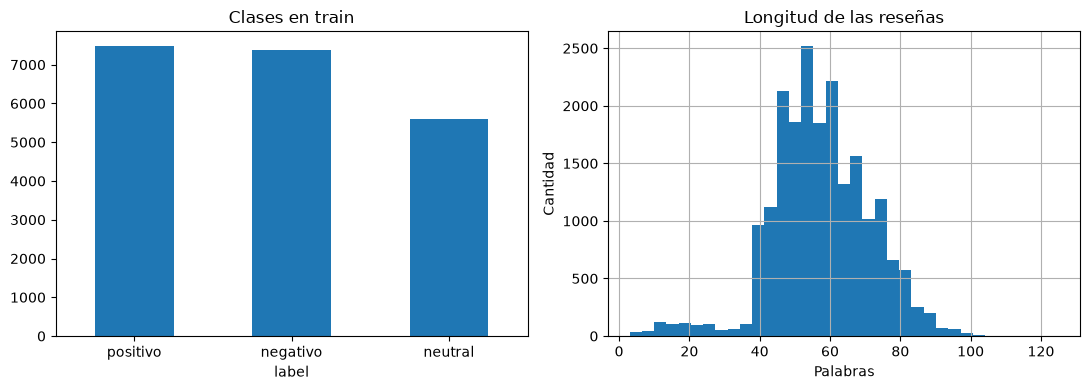

In [6]:
train["palabras"] = train["text"].str.split().str.len()
display(train.groupby("label")["palabras"].agg(["count", "mean", "median", "max"]).round(2))
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
train["label"].value_counts().plot.bar(ax=ejes[0], rot=0, title="Clases en train")
train["palabras"].hist(bins=35, ax=ejes[1])
ejes[1].set(title="Longitud de las reseñas", xlabel="Palabras", ylabel="Cantidad")
plt.tight_layout()
fig.savefig(SALIDA / "figuras/datos.png", dpi=150)
plt.show()


## 4. Estimación del idioma y partición de validación

El clasificador recibe el texto directamente: no necesita conocer el idioma. Estimamos el
idioma solo para mantener una partición razonable y analizar errores. Usamos `langid`,
restringido a los cuatro idiomas del enunciado. Para marcar posibles mezclas ES/EN usamos
una regla sencilla: al menos dos palabras distintas de una lista española y dos de una inglesa.

Estas son **etiquetas estimadas**, no idiomas verdaderos. Préstamos como *battery* pueden
crear falsos positivos y una mezcla breve puede pasar inadvertida. Guardamos ejemplos para
revisar esta limitación manualmente; no usamos la regla para asignar sentimientos.



In [7]:
detector_idiomas = LanguageIdentifier.from_modelstring(modelo_idiomas, norm_probs=True)
detector_idiomas.set_languages(["es", "en", "pt", "fr"])
marcas_es = set("compré compre llegó llego pedí pedi pero aunque estoy tengo funciona después despues".split())
marcas_en = set("the this with bought arrived works although however really because very would".split())


def estimar_idioma(texto):
    palabras = set(re.findall(r"[^\W\d_]+", texto.lower()))
    if len(palabras & marcas_es) >= 2 and len(palabras & marcas_en) >= 2:
        return "mixto_es_en"
    return detector_idiomas.classify(texto)[0]


def separar_validacion(datos):
    estratos = datos["label"] + "_" + datos["idioma_estimado"]
    # Si un subgrupo tiene una sola reseña, estratificar solo por clase.
    if estratos.value_counts().min() < 2:
        estratos = datos["label"]
    indices_train, indices_val = train_test_split(
        np.arange(len(datos)), test_size=0.20,
        random_state=RANDOM_STATE, stratify=estratos,
    )
    assert set(indices_train).isdisjoint(set(indices_val))
    assert set(datos.iloc[indices_train]["text"]).isdisjoint(set(datos.iloc[indices_val]["text"]))
    return indices_train, indices_val


In [8]:
train["idioma_estimado"] = train["text"].map(estimar_idioma)
display(pd.crosstab(train["idioma_estimado"], train["label"]))
indices_train, indices_val = separar_validacion(train)
datos_train = train.iloc[indices_train].copy()
datos_val = train.iloc[indices_val].copy()
print("Entrenamiento:", len(datos_train), "| Validación:", len(datos_val))
particion = train[["id", "idioma_estimado", "label"]].copy()
particion["particion"] = "entrenamiento"
particion.loc[indices_val, "particion"] = "validacion"
particion.to_csv(SALIDA / "particion.csv", index=False)
display(pd.crosstab(particion["idioma_estimado"], particion["particion"]))
for idioma, grupo in datos_val.groupby("idioma_estimado"):
    print("\nIdioma estimado:", idioma)
    display(grupo[["id", "text", "label"]].head(2))


label,negativo,neutral,positivo
idioma_estimado,,,
en,777,751,832
es,5044,3577,5035
fr,739,576,781
mixto_es_en,11,0,11
pt,810,695,827


Entrenamiento: 16372 | Validación: 4094


particion,entrenamiento,validacion
idioma_estimado,,
en,1888,472
es,10924,2732
fr,1677,419
mixto_es_en,18,4
pt,1865,467



Idioma estimado: en


,id,text,label
4977,4977,"Been using it for a while now, it's running no...",neutral
11542,11542,The battery genuinely lasts me five days with ...,positivo



Idioma estimado: es


... (3 outputs left out)


Idioma estimado: mixto_es_en


,id,text,label
8719,8719,El colchón llegó súper fast y the firmness is ...,positivo
6695,6695,Compré este set de sartenes el mes pasado para...,negativo



Idioma estimado: pt


,id,text,label
9687,9687,Comprei essa cafetera mês passado pra substitu...,positivo
4547,4547,Pedi numa terça e chegou na quinta no escritór...,positivo


## 5. Aumento de datos: un error de escritura leve

Seleccionamos un 50% de las reseñas de entrenamiento con semilla 42. En cada una intentamos
intercambiar dos letras interiores distintas de una sola palabra de siete o más letras.
Conservamos primera y última letra, puntuación, orden de palabras y etiqueta original.
Protegemos negaciones en los cuatro idiomas y no eliminamos stopwords.

La hipótesis es que un error pequeño conserva la opinión y ayuda con faltas de escritura.
No es una garantía: puede dificultar una palabra importante. Mostramos ejemplos y medimos
su efecto; no damos por hecho que mejora. Las versiones sin un cambio real se descartan.

**Primero se separa la validación.** Durante la comparación, ninguna copia procede de
validación ni de `eval.csv`. En el reentrenamiento final sí se usa todo `train.csv`.



In [9]:
negaciones = set("no nunca jamás jamas ni nada nadie ninguno ninguna ningún ningun tampoco sin not never neither nor nothing nobody nowhere without don't doesn't didn't isn't wasn't wouldn't couldn't shouldn't cannot can't won't nao não nunca jamais nem nada ninguém ninguem nenhum nenhuma sem ne pas jamais rien personne aucun aucune sans non".split())


def error_tipografico(texto, generador):
    opciones = []
    for palabra in re.finditer(r"[^\W\d_]+", texto):
        termino = palabra.group()
        if len(termino) >= 7 and termino.lower() not in negaciones:
            posiciones = [i for i in range(1, len(termino) - 2) if termino[i] != termino[i + 1]]
            if posiciones:
                opciones.append((palabra, posiciones))
    if not opciones:
        return texto
    palabra, posiciones = generador.choice(opciones)
    posicion = generador.choice(posiciones)
    letras = list(palabra.group())
    letras[posicion], letras[posicion + 1] = letras[posicion + 1], letras[posicion]
    return texto[:palabra.start()] + "".join(letras) + texto[palabra.end():]


def aumentar_datos(datos, fraccion=FRACCION_AUMENTO):
    generador = random.Random(RANDOM_STATE)
    seleccion = datos.sample(frac=fraccion, random_state=RANDOM_STATE)
    originales = set(datos["text"])
    filas = []
    for _, fila in seleccion.iterrows():
        nuevo = error_tipografico(fila["text"], generador)
        if nuevo != fila["text"] and nuevo not in originales:
            filas.append({"id_origen": int(fila["id"]), "original": fila["text"],
                          "text": nuevo, "label": fila["label"]})
    return pd.DataFrame(filas, columns=["id_origen", "original", "text", "label"]).drop_duplicates("text")


In [10]:
aumentados_train = aumentar_datos(datos_train)
assert set(aumentados_train["id_origen"]).issubset(set(datos_train["id"]))
assert set(aumentados_train["id_origen"]).isdisjoint(set(datos_val["id"]))
assert set(aumentados_train["text"]).isdisjoint(set(datos_val["text"]))
print("Reseñas originales:", len(datos_train), "| Copias aumentadas:", len(aumentados_train))
display(aumentados_train[["original", "text", "label"]].head(10))
aumentados_train.to_csv(SALIDA / "aumento_entrenamiento.csv", index=False)


Reseñas originales: 16372 | Copias aumentadas: 8175


,original,text,label
0,"Me llegó el martes por la mañana, el paquete b...","Me llegó el martes por la mañana, el paquete b...",neutral
1,La silla de oficina llegó a tiempo y the assem...,La silla de ofiicna llegó a tiempo y the assem...,positivo
2,Comprei esse colchao mes passado pra substitui...,Comprei esse colchao mes passado pra susbtitui...,negativo
3,La compré a mediados de mes y llegó en tres dí...,La compré a mediados de mes y llegó en tres dí...,neutral
4,"Compré esto en línea a mediados de año, llegó ...","Compré esto en línea a mediados de año, llegó ...",positivo
5,Lo pedi a mediados de mes y llego en tres dias...,Lo pedi a mediados de mes y llego en tres dias...,positivo
6,"Me llegó a domicilio en cuatro días, lo compré...","Me llegó a dmoicilio en cuatro días, lo compré...",positivo
7,"O pedido chegou na quinta à tarde, comprei na ...","O pedido chegou na quinta à tarde, comprei na ...",negativo
8,Lo compré a mediados de mes porque iba a empez...,Lo compré a mediados de mes porque iba a empez...,positivo
9,"Llevo un par de meses usándolo, le di bastante...","Llevo un par de meses usándolo, le di bastante...",neutral


## 6. Embeddings contextuales con mBERT

Cargamos una revisión fija del encoder. Sus pesos quedan **congelados**: solo entrenamos
el MLP. Así extraemos los embeddings una vez y comparamos varias redes a bajo costo.
Al trabajar por lotes debemos ignorar el padding y los tokens especiales al promediar.

Comparamos tres representaciones: `[CLS]`, promedio de tokens y concatenación de ambas.
La concatenación junta dos vectores; no agrega otro Transformer.
El cache identifica textos, revisión y longitud, para no reutilizar vectores de otra ejecución.
No ajustamos un vocabulario ni un encoder con validación o con `eval`.

Fuente: [mBERT - ficha del modelo y licencia Apache 2.0](https://huggingface.co/google-bert/bert-base-multilingual-cased).



In [11]:
def resumir_tokens(ocultos, attention_mask, special_tokens_mask):
    mascara = (attention_mask.bool() & ~special_tokens_mask.bool()).unsqueeze(-1)
    promedio = (ocultos * mascara).sum(dim=1) / mascara.sum(dim=1).clamp(min=1)
    return ocultos[:, 0, :], promedio


def extraer_embeddings(textos, tokenizador, encoder, dispositivo, max_length=MAX_LENGTH):
    textos = list(textos)
    cls_lotes, promedio_lotes = [], []
    for inicio in range(0, len(textos), BATCH_EMBEDDINGS):
        lote = textos[inicio:inicio + BATCH_EMBEDDINGS]
        entradas = tokenizador(lote, padding=True, truncation=True, max_length=max_length,
                               return_special_tokens_mask=True, return_tensors="pt")
        especiales = entradas.pop("special_tokens_mask").to(dispositivo)
        entradas = {clave: valor.to(dispositivo) for clave, valor in entradas.items()}
        with torch.no_grad():
            ocultos = encoder(**entradas).last_hidden_state
            cls, promedio = resumir_tokens(ocultos, entradas["attention_mask"], especiales)
        cls_lotes.append(cls.cpu().numpy())
        promedio_lotes.append(promedio.cpu().numpy())
        if inicio % (BATCH_EMBEDDINGS * 100) == 0:
            print(f"Embeddings: {min(inicio + len(lote), len(textos))}/{len(textos)}", flush=True)
    dimension = encoder.config.hidden_size
    return {"cls": np.concatenate(cls_lotes) if cls_lotes else np.empty((0, dimension), dtype=np.float32),
            "promedio": np.concatenate(promedio_lotes) if promedio_lotes else np.empty((0, dimension), dtype=np.float32)}


def embeddings_con_cache(textos, nombre):
    textos = list(textos)
    firma = hashlib.sha256(json.dumps([MODELO_BASE, REVISION, MAX_LENGTH, textos], ensure_ascii=False).encode()).hexdigest()[:20]
    ruta = CACHE / f"{nombre}_{firma}.npz"
    if ruta.exists():
        with np.load(ruta) as archivo:
            return {"cls": archivo["cls"], "promedio": archivo["promedio"]}
    resultado = extraer_embeddings(textos, tokenizador, encoder, DISPOSITIVO)
    np.savez_compressed(ruta, **resultado)
    return resultado


def elegir_representacion(embeddings, tipo):
    if tipo == "cls_promedio":
        return np.concatenate([embeddings["cls"], embeddings["promedio"]], axis=1)
    return embeddings[tipo]


In [12]:
fuente_encoder = str(RUTA_ENCODER_LOCAL) if (RUTA_ENCODER_LOCAL / "config.json").exists() else MODELO_BASE
opciones_encoder = {"local_files_only": True} if fuente_encoder != MODELO_BASE else {"revision": REVISION}
tokenizador = AutoTokenizer.from_pretrained(fuente_encoder, **opciones_encoder)
encoder = AutoModel.from_pretrained(fuente_encoder, **opciones_encoder).to(DISPOSITIVO)
if encoder.config.model_type != "bert" or encoder.config.is_decoder or encoder.config.is_encoder_decoder:
    raise ValueError("Esta implementación requiere el encoder mBERT indicado.")
encoder.eval()
for parametro in encoder.parameters():
    parametro.requires_grad = False
print("Encoder:", MODELO_BASE, "| Dimensión:", encoder.config.hidden_size)

# Medición solo con train. No cambia la longitud automáticamente según eval.
longitudes = [len(tokenizador(texto, truncation=False)["input_ids"]) for texto in train["text"]]
recortados = float(np.mean(np.array(longitudes) > MAX_LENGTH))
print(f"Textos de train recortados a {MAX_LENGTH} tokens: {recortados:.2%}")
emb_train = embeddings_con_cache(train["text"], "train")
emb_aumento = embeddings_con_cache(aumentados_train["text"], "aumento_train")
y = train["label"].map(etiqueta_a_numero).to_numpy(dtype=np.int64)
y_aumento = aumentados_train["label"].map(etiqueta_a_numero).to_numpy(dtype=np.int64)


[transformers] The tokenizer you are loading from 'models\parte2\mbert' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  19%|█▉        | 38/199 [00:00<00:00, 356.92it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1130.73it/s]


[transformers] BertModel LOAD REPORT from: models\parte2\mbert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Encoder: google-bert/bert-base-multilingual-cased | Dimensión: 768


... (16 outputs left out)

Embeddings: 3216/8175


Embeddings: 4816/8175


Embeddings: 6416/8175


Embeddings: 8016/8175


## 7. Un MLP sencillo

La red tiene dos capas ocultas: entrada → 128 → 64 → 3. Usamos ReLU, Dropout y Adam.
La salida entrega tres puntajes y `CrossEntropyLoss` calcula internamente las probabilidades;
por eso no ponemos Softmax antes de la pérdida. Para predecir elegimos el puntaje mayor.

Estandarizamos cada componente con media y desviación aprendidas **solo en el entrenamiento
original**. En el par con/sin aumento usamos la misma transformación. La parada temprana
conserva los pesos de menor pérdida de validación y espera cuatro épocas sin mejora.



In [13]:
def construir_mlp(dimension, neuronas=128, dropout=0.20):
    return nn.Sequential(
        nn.Linear(dimension, neuronas), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(neuronas, neuronas // 2), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(neuronas // 2, len(CLASES)),
    )


def predecir_vectores(red, vectores):
    red.eval()
    predicciones = []
    with torch.no_grad():
        for inicio in range(0, len(vectores), BATCH_MLP):
            lote = torch.tensor(vectores[inicio:inicio + BATCH_MLP], dtype=torch.float32, device=DISPOSITIVO)
            predicciones.extend(red(lote).argmax(dim=1).cpu().tolist())
    return np.array(predicciones, dtype=np.int64)


def entrenar_mlp(X_train, y_train, config, X_val=None, y_val=None, epocas=EPOCAS):
    fijar_semilla()
    red = construir_mlp(X_train.shape[1], config["neuronas"], config["dropout"]).to(DISPOSITIVO)
    optimizador = torch.optim.Adam(red.parameters(), lr=config["lr"], weight_decay=1e-4)
    perdida = nn.CrossEntropyLoss()
    dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
    lotes = DataLoader(dataset, batch_size=BATCH_MLP, shuffle=True,
                       generator=torch.Generator().manual_seed(RANDOM_STATE), num_workers=0)
    mejor_perdida, mejor_epoca, sin_mejora = float("inf"), 0, 0
    mejores_pesos = None
    historia = []
    for epoca in range(1, epocas + 1):
        red.train()
        suma_perdida, aciertos = 0.0, 0
        for vectores, etiquetas in lotes:
            vectores, etiquetas = vectores.to(DISPOSITIVO), etiquetas.to(DISPOSITIVO)
            optimizador.zero_grad()
            salidas = red(vectores)
            costo = perdida(salidas, etiquetas)
            costo.backward()
            optimizador.step()
            suma_perdida += costo.item() * len(etiquetas)
            aciertos += (salidas.argmax(dim=1) == etiquetas).sum().item()
        fila = {"epoca": epoca, "loss": suma_perdida / len(dataset), "accuracy": aciertos / len(dataset)}
        if X_val is not None:
            red.eval()
            costo_val, correctos = 0.0, 0
            with torch.no_grad():
                for inicio in range(0, len(X_val), BATCH_MLP):
                    vx = torch.tensor(X_val[inicio:inicio + BATCH_MLP], dtype=torch.float32, device=DISPOSITIVO)
                    vy = torch.tensor(y_val[inicio:inicio + BATCH_MLP], dtype=torch.long, device=DISPOSITIVO)
                    salidas = red(vx)
                    costo_val += perdida(salidas, vy).item() * len(vy)
                    correctos += (salidas.argmax(dim=1) == vy).sum().item()
            fila["val_loss"] = costo_val / len(X_val)
            fila["val_accuracy"] = correctos / len(X_val)
            if fila["val_loss"] < mejor_perdida:
                mejor_perdida, mejor_epoca, sin_mejora = fila["val_loss"], epoca, 0
                mejores_pesos = deepcopy(red.state_dict())
            else:
                sin_mejora += 1
        historia.append(fila)
        print(config["nombre"], {k: round(v, 4) for k, v in fila.items()}, flush=True)
        if X_val is not None and sin_mejora >= PACIENCIA:
            break
    if mejores_pesos is not None:
        red.load_state_dict(mejores_pesos)
    else:
        mejor_epoca = epocas
    return red, pd.DataFrame(historia), mejor_epoca


## 8. Cinco experimentos

Cambiamos una decisión a la vez al inicio. E02 y E03 tienen exactamente la misma arquitectura,
semilla, partición e hiperparámetros: la diferencia es incorporar copias aumentadas.
E04 estudia una representación más completa; E05 reduce la tasa de aprendizaje frente a E04.
Las variantes permiten producir cinco candidatos, pero pueden o no mejorar: lo decide la evidencia.



In [14]:
experimentos = [
    {"nombre": "p2_exp01_cls", "representacion": "cls", "aumento": False, "neuronas": 128, "dropout": 0.20, "lr": 0.001},
    {"nombre": "p2_exp02_promedio", "representacion": "promedio", "aumento": False, "neuronas": 128, "dropout": 0.20, "lr": 0.001},
    {"nombre": "p2_exp03_promedio_aumento", "representacion": "promedio", "aumento": True, "neuronas": 128, "dropout": 0.20, "lr": 0.001},
    {"nombre": "p2_exp04_cls_promedio_aumento", "representacion": "cls_promedio", "aumento": True, "neuronas": 128, "dropout": 0.20, "lr": 0.001},
    {"nombre": "p2_exp05_lr_aumento", "representacion": "cls_promedio", "aumento": True, "neuronas": 128, "dropout": 0.20, "lr": 0.0003},
]
display(pd.DataFrame(experimentos))
resultados, modelos_val, historiales, predicciones_val = [], {}, {}, {}
for config in experimentos:
    inicio = time.time()
    vectores = elegir_representacion(emb_train, config["representacion"])
    escala = StandardScaler().fit(vectores[indices_train])
    X_train = escala.transform(vectores[indices_train]).astype(np.float32)
    X_val = escala.transform(vectores[indices_val]).astype(np.float32)
    y_train = y[indices_train].copy()
    if config["aumento"] and len(aumentados_train):
        X_extra = elegir_representacion(emb_aumento, config["representacion"])
        X_train = np.concatenate([X_train, escala.transform(X_extra).astype(np.float32)])
        y_train = np.concatenate([y_train, y_aumento])
    red, historia, epoca = entrenar_mlp(X_train, y_train, config, X_val, y[indices_val])
    pred = predecir_vectores(red, X_val)
    nombre = config["nombre"]
    resultados.append({**config, "accuracy_val": accuracy_score(y[indices_val], pred),
                       "mejor_epoca": epoca, "n_entrenamiento": len(y_train), "segundos": time.time() - inicio})
    modelos_val[nombre] = red
    historiales[nombre] = historia
    predicciones_val[nombre] = pred
    historia.to_csv(SALIDA / f"historia_{nombre}.csv", index=False)

tabla = pd.DataFrame(resultados).sort_values("accuracy_val", ascending=False).reset_index(drop=True)
tabla.to_csv(SALIDA / "resultados_validacion.csv", index=False)
display(tabla)


,nombre,representacion,aumento,neuronas,dropout,lr
0,p2_exp01_cls,cls,False,128,0.2,0.0010
1,p2_exp02_promedio,promedio,False,128,0.2,0.0010
2,p2_exp03_promedio_aumento,promedio,True,128,0.2,0.0010
3,p2_exp04_cls_promedio_aumento,cls_promedio,True,128,0.2,0.0010
4,p2_exp05_lr_aumento,cls_promedio,True,128,0.2,0.0003


p2_exp01_cls {'epoca': 1, 'loss': 0.6934, 'accuracy': 0.614, 'val_loss': 0.5969, 'val_accuracy': 0.6639}


p2_exp01_cls {'epoca': 2, 'loss': 0.5778, 'accuracy': 0.6812, 'val_loss': 0.5659, 'val_accuracy': 0.6903}


p2_exp01_cls {'epoca': 3, 'loss': 0.554, 'accuracy': 0.6967, 'val_loss': 0.5631, 'val_accuracy': 0.6854}


p2_exp01_cls {'epoca': 4, 'loss': 0.529, 'accuracy': 0.7184, 'val_loss': 0.5458, 'val_accuracy': 0.6971}


p2_exp01_cls {'epoca': 5, 'loss': 0.5109, 'accuracy': 0.7214, 'val_loss': 0.5436, 'val_accuracy': 0.703}


... (45 outputs left out)

p2_exp05_lr_aumento {'epoca': 8, 'loss': 0.3863, 'accuracy': 0.8085, 'val_loss': 0.5373, 'val_accuracy': 0.7189}


p2_exp05_lr_aumento {'epoca': 9, 'loss': 0.3682, 'accuracy': 0.8217, 'val_loss': 0.5447, 'val_accuracy': 0.7181}


p2_exp05_lr_aumento {'epoca': 10, 'loss': 0.3527, 'accuracy': 0.833, 'val_loss': 0.5577, 'val_accuracy': 0.7215}


,nombre,representacion,aumento,neuronas,dropout,lr,accuracy_val,mejor_epoca,n_entrenamiento,segundos
0,p2_exp05_lr_aumento,cls_promedio,True,128,0.2,0.0003,0.717880,6,24547,8.044777
1,p2_exp04_cls_promedio_aumento,cls_promedio,True,128,0.2,0.0010,0.703957,3,24547,6.485489
2,p2_exp01_cls,cls,False,128,0.2,0.0010,0.700537,6,16372,5.505726
3,p2_exp03_promedio_aumento,promedio,True,128,0.2,0.0010,0.694919,6,24547,7.545221
4,p2_exp02_promedio,promedio,False,128,0.2,0.0010,0.693698,12,16372,7.925865


## 9. Efecto del aumento y análisis de errores

Reportamos el cambio de accuracy en puntos porcentuales, tanto globalmente como por idioma
estimado. La validación conserva las reseñas originales y es idéntica en los cinco experimentos.
Una comparación con una sola semilla es evidencia inicial, no una demostración de significancia.



Sin aumento: 0.69370 | Con aumento: 0.69492 | Diferencia: +0.12 pp
Mejor candidato en validación: p2_exp05_lr_aumento
              precision    recall  f1-score   support

    negativo       0.62      0.64      0.63      1476
     neutral       0.97      0.96      0.97      1120
    positivo       0.63      0.61      0.62      1498

    accuracy                           0.72      4094
   macro avg       0.74      0.74      0.74      4094
weighted avg       0.72      0.72      0.72      4094



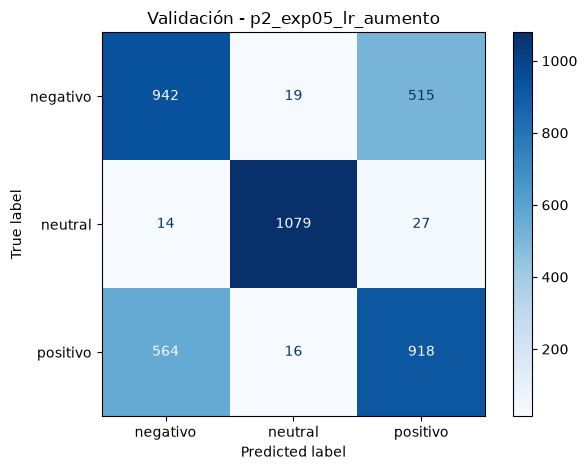

,idioma_estimado,n,accuracy_mejor,accuracy_sin_aumento,accuracy_con_aumento,cambio_pp
0,en,472,0.709746,0.697034,0.726695,2.966102
1,es,2732,0.729502,0.699122,0.698389,-0.073206
2,fr,419,0.687351,0.684964,0.673031,-1.193317
3,mixto_es_en,4,0.250000,0.500000,0.250000,-25.000000
4,pt,467,0.689507,0.668094,0.665953,-0.214133



Errores del idioma estimado: en


,text,label,prediccion
2992,"It arrived on Friday afternoon, two days after...",positivo,negativo
2952,Bought this keyboard three weeks ago for my la...,negativo,positivo
452,Bought these running shoes two months ago for ...,positivo,negativo


              precision    recall  f1-score   support

    negativo       0.57      0.59      0.58       155
     neutral       0.96      0.97      0.96       150
    positivo       0.61      0.59      0.60       167

    accuracy                           0.71       472
   macro avg       0.71      0.72      0.71       472
weighted avg       0.71      0.71      0.71       472


Errores del idioma estimado: es


,text,label,prediccion
418,"Lo pedi en la tienda fisica, fue un sabado por...",neutral,positivo
836,Escribo con calma mi opinion. Compre esto en l...,negativo,positivo
310,Compré esto el mes pasado para un proyecto en ...,positivo,negativo


              precision    recall  f1-score   support

    negativo       0.63      0.71      0.67      1009
     neutral       0.97      0.97      0.97       716
    positivo       0.66      0.58      0.62      1007

    accuracy                           0.73      2732
   macro avg       0.75      0.75      0.75      2732
weighted avg       0.73      0.73      0.73      2732


Errores del idioma estimado: fr


... (2 outputs left out)

,text,label,prediccion
153,El colchón llegó súper fast y the firmness is ...,positivo,negativo
980,Compré este set de sartenes el mes pasado para...,negativo,positivo
3442,El colchón llegó rápido y la entrega fue super...,positivo,negativo


              precision    recall  f1-score   support

    negativo       0.33      0.50      0.40         2
     neutral       0.00      0.00      0.00         0
    positivo       0.00      0.00      0.00         2

    accuracy                           0.25         4
   macro avg       0.11      0.17      0.13         4
weighted avg       0.17      0.25      0.20         4


Errores del idioma estimado: pt


,text,label,prediccion
1898,Compré essa câmera de segurança pro portão de ...,negativo,positivo
3996,Comprei depois de várias semanas procurando po...,positivo,negativo
533,Vim deixar minha opinião. Comprei essa memória...,positivo,negativo


              precision    recall  f1-score   support

    negativo       0.59      0.47      0.52       162
     neutral       0.94      0.96      0.95       139
    positivo       0.57      0.67      0.62       166

    accuracy                           0.69       467
   macro avg       0.70      0.70      0.70       467
weighted avg       0.69      0.69      0.69       467



In [15]:
sin_aumento = tabla.set_index("nombre").loc["p2_exp02_promedio", "accuracy_val"]
con_aumento = tabla.set_index("nombre").loc["p2_exp03_promedio_aumento", "accuracy_val"]
diferencia = 100 * (con_aumento - sin_aumento)
print(f"Sin aumento: {sin_aumento:.5f} | Con aumento: {con_aumento:.5f} | Diferencia: {diferencia:+.2f} pp")

mejor_nombre = tabla.loc[0, "nombre"]
pred_mejor = predicciones_val[mejor_nombre]
print("Mejor candidato en validación:", mejor_nombre)
print(classification_report(y[indices_val], pred_mejor, labels=[0, 1, 2], target_names=CLASES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y[indices_val], pred_mejor, labels=[0, 1, 2], display_labels=CLASES, cmap="Blues")
plt.title(f"Validación - {mejor_nombre}")
plt.tight_layout()
plt.savefig(SALIDA / "figuras/matriz_confusion.png", dpi=150)
plt.show()

diagnostico = datos_val[["id", "text", "label", "idioma_estimado"]].reset_index(drop=True)
diagnostico["prediccion"] = [CLASES[i] for i in pred_mejor]
diagnostico["acierto"] = diagnostico["label"] == diagnostico["prediccion"]
por_idioma = []
for idioma, grupo in diagnostico.groupby("idioma_estimado"):
    mascara = diagnostico["idioma_estimado"].eq(idioma).to_numpy()
    acc_sin = accuracy_score(y[indices_val][mascara], predicciones_val["p2_exp02_promedio"][mascara])
    acc_con = accuracy_score(y[indices_val][mascara], predicciones_val["p2_exp03_promedio_aumento"][mascara])
    por_idioma.append({"idioma_estimado": idioma, "n": len(grupo), "accuracy_mejor": grupo["acierto"].mean(),
                       "accuracy_sin_aumento": acc_sin, "accuracy_con_aumento": acc_con, "cambio_pp": 100 * (acc_con - acc_sin)})
tabla_idiomas = pd.DataFrame(por_idioma)
display(tabla_idiomas)
tabla_idiomas.to_csv(SALIDA / "resultados_por_idioma.csv", index=False)
diagnostico.to_csv(SALIDA / "predicciones_validacion.csv", index=False)
errores = diagnostico[~diagnostico["acierto"]].copy()
errores.to_csv(SALIDA / "errores_validacion.csv", index=False)
for idioma, grupo in errores.groupby("idioma_estimado"):
    print("\nErrores del idioma estimado:", idioma)
    display(grupo.sample(n=min(3, len(grupo)), random_state=RANDOM_STATE)[["text", "label", "prediccion"]])
    mascara = diagnostico["idioma_estimado"].eq(idioma).to_numpy()
    print(classification_report(y[indices_val][mascara], pred_mejor[mascara], labels=[0, 1, 2], target_names=CLASES, zero_division=0))


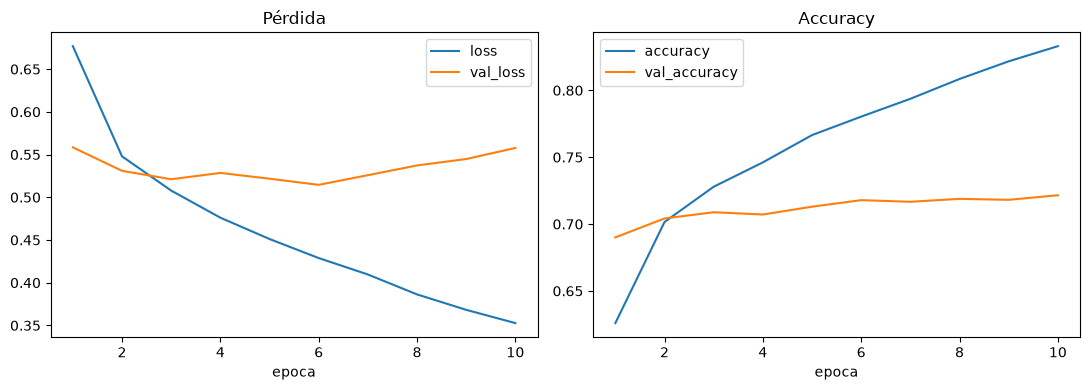

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
historia = historiales[mejor_nombre]
historia.plot(x="epoca", y=["loss", "val_loss"], ax=ejes[0], title="Pérdida")
historia.plot(x="epoca", y=["accuracy", "val_accuracy"], ax=ejes[1], title="Accuracy")
plt.tight_layout()
fig.savefig(SALIDA / "figuras/curvas_aprendizaje.png", dpi=150)
plt.show()


### Análisis de la ejecución completa del 18 de noviembre de 2026

La validación contiene 4.094 reseñas originales y el mejor candidato, `p2_exp05_lr_aumento`,
acertó 2.939: accuracy de **0,71788**. Usar CLS solo dio 0,70054 y promedio solo dio 0,69370.
En esta partición no se cumplió la idea de que promediar siempre sería mejor que usar CLS.
Concatenar ambas representaciones con aumento dio 0,70396; reducir la tasa de aprendizaje
de 0,001 a 0,0003 elevó ese resultado a 0,71788. Esta es la mejora más clara de la secuencia.

La matriz de confusión muestra que 1.079 de los 1.155 errores son intercambios entre
positivo y negativo: 515 negativos se predicen positivos y 564 positivos se predicen
negativos. La clase neutral tiene 1.079 aciertos de 1.120 casos, por lo que separar las
reseñas descriptivas funciona bastante mejor que resolver la polaridad de las opiniones.
Las curvas muestran sobreajuste: la pérdida de entrenamiento sigue bajando mientras
la de validación vuelve a subir después de la época 6. Por eso se restauran los pesos
de esa época y se usan seis épocas para reentrenar el candidato final.

El par controlado sin/con aumento pasó de 0,69370 a 0,69492: **cinco aciertos adicionales**,
o **+0,12 puntos porcentuales**. En inglés mejoró 2,97 puntos, pero en francés bajó 1,19;
en español y portugués los cambios fueron menores a un cuarto de punto. El efecto no es
uniforme entre idiomas y una sola partición no demuestra que el aumento mejore siempre.
También cambia la cantidad de actualizaciones por época al agregar reseñas, por lo que
esta comparación mide el procedimiento completo de aumento con el mismo límite de épocas.

**Español estimado: 72,95% de accuracy (n=2.732).** En la reseña 1026 la etiqueta es
positiva: primero critica la nitidez de imagen, pero después elogia el motor con una
concesión. El modelo predice negativo. Un vector que resume toda la reseña conserva los
dos tonos y el MLP no siempre identifica cuál domina. La reseña 3636 contiene frases en
inglés, aunque el detector la agrupó como español. Esto muestra que la regla de mezclas
es conservadora y que las cifras por idioma no son una evaluación con idiomas anotados.

**Inglés estimado: 70,97% (n=472).** La reseña 6339 tiene etiqueta negativa, pero el
modelo predice positivo: el elogio al motor convive con una crítica al cargador. En la
11542 la batería dura varios días, la pantalla falla al aire libre y el comprador expresa
indecisión. Su etiqueta es positiva y el modelo predice negativo. La coexistencia de
opiniones opuestas dificulta distinguir la opinión global; no estamos cambiando las
etiquetas del conjunto para resolver esa ambigüedad.

**Francés estimado: 68,74% (n=419).** La reseña 6265 dice que el soporte resolvió el problema
y que no hay ninguna queja: su etiqueta es positiva, pero se predice negativo. Es un
ejemplo concreto de una negación asociada a una palabra de queja. En la 10308 se menciona
un cambio sin problemas y buen sonido, pero finalmente el producto vuelve al servicio
técnico y deja de usarse. La etiqueta es negativa y el modelo predice positivo: no da el
peso necesario a la consecuencia final.

**Portugués estimado: 68,95% (n=467).** La reseña 4907 usa negaciones como «Não é que eu
goste» y «Não diria que o preço é bom». La etiqueta es negativa y se predice positivo.
No basta con reconocer palabras de elogio si están dentro de una negación. La 3351 combina
ventajas de las sartenes con cabos flojos y dudas sobre devolverlas; también se predice
positivo cuando la etiqueta es negativa. Se repite el problema de ponderar elogios frente
al juicio global y las concesiones.

**Mezcla ES/EN estimada: un acierto de cuatro ejemplos.** La reseña 6695 declara
insatisfacción en inglés y describe problemas con las asas, pero el modelo predice positivo.
Es un caso útil para inspeccionar; **cuatro reseñas son insuficientes para generalizar**.
Además, la 3636 demuestra que otras mezclas quedaron dentro del grupo español.

No se recortó ningún texto original de entrenamiento con el límite de 192 tokens. Por eso,
en esta ejecución, los errores observados no se explican por truncamiento de esas reseñas.
El uso de embeddings congelados reduce el costo y permite comparar el MLP fácilmente,
pero no adapta el encoder a las negaciones y contrastes particulares de estos datos.
Los resultados aquí descritos son de validación interna; todavía no son scores de Kaggle.


In [17]:
peor_idioma = tabla_idiomas.sort_values("accuracy_mejor").iloc[0]
efecto = "mejoró" if diferencia > 0 else "redujo" if diferencia < 0 else "no cambió"
resumen = (
    f"El mejor candidato local fue **{mejor_nombre}**, con accuracy **{tabla.loc[0, 'accuracy_val']:.5f}**. "
    f"El aumento {efecto} la accuracy en **{diferencia:+.2f} puntos porcentuales** frente al mismo MLP sin aumento. "
    f"El grupo de menor accuracy fue **{peor_idioma['idioma_estimado']}** "
    f"({peor_idioma['accuracy_mejor']:.5f}, n={int(peor_idioma['n'])}). "
    f"Se recortó el **{100 * recortados:.2f}%** de los textos de train. "
    "Los embeddings congelados reducen el costo, pero no se adaptan a las expresiones particulares del conjunto. "
    "Este resultado local no determina el orden del leaderboard privado."
)
if MODO_PRUEBA:
    resumen = "**PRUEBA REDUCIDA: estas cifras no corresponden al proyecto completo.**\n\n" + resumen
display(Markdown(resumen))
(SALIDA / "conclusiones_validacion.md").write_text(resumen, encoding="utf-8")


El mejor candidato local fue **p2_exp05_lr_aumento**, con accuracy **0.71788**. El aumento mejoró la accuracy en **+0.12 puntos porcentuales** frente al mismo MLP sin aumento. El grupo de menor accuracy fue **mixto_es_en** (0.25000, n=4). Se recortó el **0.00%** de los textos de train. Los embeddings congelados reducen el costo, pero no se adaptan a las expresiones particulares del conjunto. Este resultado local no determina el orden del leaderboard privado.

462

## 10. Reentrenamiento y cinco candidatos para Kaggle

Después de fijar las configuraciones y las épocas con validación, reentrenamos cada MLP
desde cero con todo `train.csv`. Ahora no hay validación reservada, así que usamos el número
de épocas seleccionado antes, sin consultar `eval`. Para los modelos con aumento, generamos
copias a partir de todo train. Las versiones aumentadas ya calculadas se reutilizan.

Guardamos un checkpoint por candidato para que el modelo entregado sea exactamente el que
produjo el archivo enviado. Extraer embeddings de eval es inferencia con el encoder congelado;
no se calcula ningún ajuste, etiqueta ni aumento a partir de ese archivo.



In [18]:
def guardar_checkpoint(ruta, red, escala, config, epocas):
    checkpoint = {
        "pesos": {k: v.detach().cpu() for k, v in red.state_dict().items()},
        "media": torch.tensor(escala.mean_, dtype=torch.float32),
        "escala": torch.tensor(escala.scale_, dtype=torch.float32),
        "config": config, "dimension": int(len(escala.mean_)),
        "clases": CLASES, "modelo_base": MODELO_BASE, "revision": REVISION,
        "max_length": MAX_LENGTH, "semilla": RANDOM_STATE, "epocas": int(epocas),
        "modo_prueba": MODO_PRUEBA,
    }
    torch.save(checkpoint, ruta)


def cargar_checkpoint(ruta):
    checkpoint = torch.load(ruta, map_location="cpu", weights_only=True)
    config = checkpoint["config"]
    red = construir_mlp(checkpoint["dimension"], config["neuronas"], config["dropout"])
    red.load_state_dict(checkpoint["pesos"])
    red = red.to(DISPOSITIVO).eval()
    return red, checkpoint


def predecir_checkpoint(red, checkpoint, embeddings):
    vectores = elegir_representacion(embeddings, checkpoint["config"]["representacion"])
    media = checkpoint["media"].numpy()
    escala = checkpoint["escala"].numpy()
    normalizados = ((vectores - media) / escala).astype(np.float32)
    return np.array(checkpoint["clases"])[predecir_vectores(red, normalizados)]


In [19]:
aumentados_full = aumentar_datos(train)
# Reutilizar las copias ya calculadas cuando el texto coincida exactamente.
emb_extra_full = {"cls": [], "promedio": []}
ya_extraidos = {texto: i for i, texto in enumerate(aumentados_train["text"])}
pendientes = [texto for texto in aumentados_full["text"] if texto not in ya_extraidos]
emb_pendientes = embeddings_con_cache(pendientes, "aumento_full_pendiente")
indice_pendiente = {texto: i for i, texto in enumerate(pendientes)}
for texto in aumentados_full["text"]:
    origen = emb_aumento if texto in ya_extraidos else emb_pendientes
    indice = ya_extraidos[texto] if texto in ya_extraidos else indice_pendiente[texto]
    for tipo in emb_extra_full:
        emb_extra_full[tipo].append(origen[tipo][indice])
emb_extra_full = {tipo: np.array(valores, dtype=np.float32).reshape(-1, encoder.config.hidden_size)
                  for tipo, valores in emb_extra_full.items()}
y_extra_full = aumentados_full["label"].map(etiqueta_a_numero).to_numpy(dtype=np.int64)
aumentados_full.to_csv(SALIDA / "aumento_final.csv", index=False)
emb_eval = embeddings_con_cache(eval_df["text"], "eval_inferencia")
registro = []
for config in experimentos:
    nombre = config["nombre"]
    vectores = elegir_representacion(emb_train, config["representacion"])
    escala = StandardScaler().fit(vectores)
    X_full = escala.transform(vectores).astype(np.float32)
    y_full = y.copy()
    if config["aumento"] and len(aumentados_full):
        extra = elegir_representacion(emb_extra_full, config["representacion"])
        X_full = np.concatenate([X_full, escala.transform(extra).astype(np.float32)])
        y_full = np.concatenate([y_full, y_extra_full])
    epocas_final = int(tabla.set_index("nombre").loc[nombre, "mejor_epoca"])
    red_full, _, _ = entrenar_mlp(X_full, y_full, config, epocas=epocas_final)
    ruta_modelo = SALIDA / "modelos" / f"{nombre}.pt"
    guardar_checkpoint(ruta_modelo, red_full, escala, config, epocas_final)
    # Las predicciones salen del checkpoint RECARGADO, no de pesos temporales.
    red_guardada, checkpoint = cargar_checkpoint(ruta_modelo)
    pred_eval = predecir_checkpoint(red_guardada, checkpoint, emb_eval)
    submission = crear_submission(eval_df, sample_submission, pred_eval)
    ruta_csv = SALIDA / "submissions" / f"{nombre}.csv"
    submission.to_csv(ruta_csv, index=False)
    firma = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()
    registro.append({"experimento": nombre, "archivo": ruta_csv.name, "sha256": firma,
                     "accuracy_val": float(tabla.set_index("nombre").loc[nombre, "accuracy_val"])})
    print("Guardado:", ruta_csv)
pd.DataFrame(registro).to_csv(SALIDA / "archivos_generados.csv", index=False)
firmas_distintas = len({fila["sha256"] for fila in registro})
print("Candidatos con predicciones distintas:", firmas_distintas, "/", len(registro))
if firmas_distintas < 5:
    print("Hay candidatos idénticos: no contarlos como cinco soluciones diferentes; revisar las configuraciones.")


Embeddings: 16/10129


Embeddings: 1616/10129


Embeddings: 3216/10129


Embeddings: 4816/10129


Embeddings: 6416/10129


Embeddings: 8016/10129


... (40 outputs left out)

p2_exp05_lr_aumento {'epoca': 4, 'loss': 0.4731, 'accuracy': 0.7458}


p2_exp05_lr_aumento {'epoca': 5, 'loss': 0.4522, 'accuracy': 0.763}


p2_exp05_lr_aumento {'epoca': 6, 'loss': 0.4322, 'accuracy': 0.7751}


Guardado: output\parte2\submissions\p2_exp05_lr_aumento.csv
Candidatos con predicciones distintas: 5 / 5


## 11. Resultados públicos y selección del modelo final

Subir los CSV en la pestaña **Submit Prediction** de la competencia de la parte 2.
Registrar cada envío en `registro_kaggle.csv` con score, fecha e ID de submission.
Ese registro permanece vacío hasta obtener resultados reales. No copiar scores de la parte 1.

La selección usa el mejor score público, como pide el enunciado; los empates se resuelven
con la accuracy local. Sin scores, el archivo final queda marcado como **provisional**.
El score privado usa otros ejemplos: mejorar el público no garantiza superar la línea base privada.



In [20]:
RUTA_REGISTRO = SALIDA / "registro_kaggle.csv"
if not RUTA_REGISTRO.exists():
    pd.DataFrame({"experimento": [c["nombre"] for c in experimentos], "accuracy_publica": np.nan,
                  "fecha_envio": "", "submission_id": ""}).to_csv(RUTA_REGISTRO, index=False)
kaggle = pd.read_csv(RUTA_REGISTRO)
if kaggle["experimento"].duplicated().any() or not set(kaggle["experimento"]).issubset(set(tabla["nombre"])):
    raise ValueError("El registro debe contener un solo resultado por candidato conocido.")
scores = pd.to_numeric(kaggle["accuracy_publica"], errors="raise")
if not scores.dropna().between(0, 1).all():
    raise ValueError("Los scores deben estar entre 0 y 1.")
kaggle["accuracy_publica"] = scores
comparacion = tabla.merge(kaggle, left_on="nombre", right_on="experimento", how="left")
display(comparacion[["nombre", "accuracy_val", "accuracy_publica", "fecha_envio", "submission_id"]])
con_score = comparacion.dropna(subset=["accuracy_publica"])
provisional = con_score.empty
if provisional:
    nombre_final = mejor_nombre
else:
    nombre_final = con_score.sort_values(["accuracy_publica", "accuracy_val"], ascending=False).iloc[0]["nombre"]
print("Modelo seleccionado:", nombre_final, "| Provisional:", provisional)
print("Envíos con score registrado:", len(con_score), "(se requieren al menos cinco envíos diferentes)")


,nombre,accuracy_val,accuracy_publica,fecha_envio,submission_id
0,p2_exp05_lr_aumento,0.717880,NaN,NaN,NaN
1,p2_exp04_cls_promedio_aumento,0.703957,NaN,NaN,NaN
2,p2_exp01_cls,0.700537,NaN,NaN,NaN
3,p2_exp03_promedio_aumento,0.694919,NaN,NaN,NaN
4,p2_exp02_promedio,0.693698,NaN,NaN,NaN


Modelo seleccionado: p2_exp05_lr_aumento | Provisional: True
Envíos con score registrado: 0 (se requieren al menos cinco envíos diferentes)


## 12. Guardado y comprobación de la entrega

Incluimos el encoder, su tokenizador y el MLP entrenado. El `.pt` contiene los pesos del
clasificador, la estandarización y los parámetros necesarios para reconstruirlo.
`save_pretrained` guarda mBERT para repetir la inferencia sin descargarlo de nuevo.
El notebook prueba otra vez el modelo desde esos archivos y compara todo el submission.



In [21]:
ENTREGA = SALIDA / "entrega"
ENTREGA.mkdir(exist_ok=True)
shutil.copy2(SALIDA / "modelos" / f"{nombre_final}.pt", ENTREGA / "modelo_final.pt")
shutil.copy2(SALIDA / "submissions" / f"{nombre_final}.csv", ENTREGA / "submission_FINAL_parte2.csv")
encoder.save_pretrained(ENTREGA / "encoder", safe_serialization=True)
tokenizador.save_pretrained(ENTREGA / "encoder")

red_recargada, checkpoint = cargar_checkpoint(ENTREGA / "modelo_final.pt")
tokenizador_recargado = AutoTokenizer.from_pretrained(ENTREGA / "encoder", local_files_only=True)
encoder_recargado = AutoModel.from_pretrained(ENTREGA / "encoder", local_files_only=True).to(DISPOSITIVO).eval()
emb_prueba = extraer_embeddings(eval_df["text"].head(5), tokenizador_recargado, encoder_recargado,
                               DISPOSITIVO, max_length=checkpoint["max_length"])
pred_prueba = predecir_checkpoint(red_recargada, checkpoint, emb_prueba)
pred_guardadas = predecir_checkpoint(red_recargada, checkpoint, emb_eval)
assert np.array_equal(pred_prueba, pred_guardadas[:5])
reproducido = crear_submission(eval_df, sample_submission, pred_guardadas)
en_disco = pd.read_csv(ENTREGA / "submission_FINAL_parte2.csv")
pd.testing.assert_frame_equal(reproducido, en_disco)
print("Modelo recargado: predicciones y CSV coinciden.")

versiones = {nombre: importlib.metadata.version(nombre) for nombre in
             ["numpy", "pandas", "matplotlib", "scikit-learn", "torch", "transformers", "langid"]}
manifiesto = {"experimento": nombre_final, "provisional": bool(provisional), "modo_prueba": MODO_PRUEBA,
              "modelo_base": MODELO_BASE, "revision": REVISION, "semilla": RANDOM_STATE,
              "max_length": MAX_LENGTH, "fraccion_aumento": FRACCION_AUMENTO,
              "accuracy_validacion": float(tabla.set_index("nombre").loc[nombre_final, "accuracy_val"]),
              "accuracy_publica": None if provisional else float(con_score.set_index("nombre").loc[nombre_final, "accuracy_publica"]),
              "python": sys.version, "versiones": versiones,
              "datos_sha256": {nombre: hashlib.sha256((DATA_DIR / nombre).read_bytes()).hexdigest()
                                for nombre in ["train.csv", "eval.csv", "sample_submission.csv"]}}
(ENTREGA / "configuracion.json").write_text(json.dumps(manifiesto, indent=2, ensure_ascii=False), encoding="utf-8")
(SALIDA / "versiones_ejecucion.txt").write_text("\n".join(f"{k}=={v}" for k, v in versiones.items()), encoding="utf-8")
print("Entregables:", ENTREGA.resolve())


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.39it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.39it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  17%|█▋        | 34/199 [00:00<00:00, 304.83it/s]

Loading weights:  33%|███▎      | 65/199 [00:00<00:00, 284.61it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 837.98it/s]

Embeddings: 5/5


Modelo recargado: predicciones y CSV coinciden.
Entregables: C:\Users\USER\Documents\UNIANDES\SEMESTRE 7\AM\PROYECTO-AM-GRUPO20\output\parte2\entrega


## 13. Referencias, límites y uso de IA

- Datos: Rubén Manrique y equipo del curso, [competencia de la parte 2](https://www.kaggle.com/competitions/parte-2-competencia-aprendizaje-de-maquina-2026-20/data).
  Licencia publicada: [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). No agregamos datasets externos.
- Encoder: Google, [bert-base-multilingual-cased](https://huggingface.co/google-bert/bert-base-multilingual-cased), Apache 2.0.
  El preentrenamiento del modelo se reutiliza; no descargamos Wikipedia como dataset adicional.
- Idiomas: Marco Lui y Timothy Baldwin, [langid.py](https://github.com/saffsd/langid.py),
  [BSD de 2 cláusulas](https://github.com/saffsd/langid.py/blob/master/LICENSE), usado solo para diagnóstico.
- Material del curso: práctica de embeddings (202610), MLP (202620) y preparación de textos (202620).
- Se utilizó **OpenAI Codex** para revisar el enunciado y el material, proponer e implementar el flujo,
  redactar documentación y comprobar el código. No se usó un modelo generativo para generar o
  etiquetar las reseñas de entrenamiento, validación o evaluación; el aumento es una regla de caracteres.
  El grupo debe revisar y comprender el código y ajustar esta declaración si incorpora otro uso de IA.

La comparación usa una sola partición. Los idiomas son estimados y el aumento puede introducir ruido.
No se afirma que se haya superado la línea base privada ni que se hayan realizado envíos sin evidencia.
El documento adicional `referencias_parte2.pdf` desarrolla las fuentes, licencias y el uso de IA.

Para la entrega: guardar este notebook ejecutado, adjuntar la carpeta `entrega/` y el documento
de referencias, revisar los errores por idioma y conservar evidencia de los cinco envíos en Kaggle.
